# Notebook 05c — Crack-Occlusion Control (corrected)

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 05c of 12

---

### Why this notebook exists

The control in notebook 05b returned an impossible result: masking the crack *improved* four-class
macro F1 from 0.743 to 0.896 and binary from 0.872 to **0.998**.

The cause was the control itself. The occlusion painted over the crack region and nothing else, so
every cracked egg acquired a smooth synthetic patch and every intact egg did not. The patch became
a cleaner label than the crack, and the model learned it. 0.998 on binary detection is not a model
reading context — it is a model reading my bug.

The corrected design, now in `src/common/data.py`, removes both cues:

* **a fixed-size square**, identical for every egg, so the *size and shape* of the occlusion carry
  no class information
* applied to **every egg**, centred on the crack where there is one and placed near the centre of
  the egg where there is not, so the *presence* of an occlusion carries no class information

The only thing the control removes is the crack itself. That is what makes the comparison valid.

### The coverage problem, and how it is handled

A fixed square cannot cover every crack, because cracks vary enormously in extent. Measured against
your annotation polygons at 384 px:

| square size | % of frame occluded | % of cracks fully covered |
|---|---|---|
| 0.45 × S = 172 px | 20 % | 64.8 % |
| 0.55 × S = 211 px | 30 % | 84.2 % |
| **0.65 × S = 249 px** | **42 %** | **94.6 %** |
| 0.75 × S = 288 px | 56 % | 98.8 % |

Partial coverage biases the result in the dangerous direction: a crack that is still half visible
lets the model keep detecting it, the control score stays high, and we would wrongly conclude the
model does not need the crack. So this notebook does two things rather than one.

1. Runs the control at **two square sizes**, 0.45 and 0.65, so the trend with coverage is visible.
2. Reports a **subset analysis restricted to eggs whose crack is fully covered**, where the crack
   is definitely gone and the comparison is unambiguous.

### How to read the outcome

The augmented acquisition floor from notebook 03 is 0.295 four-class and 0.565 binary — what
capture statistics alone achieve. The clean model reaches 0.743 and 0.872.

| occluded result | interpretation |
|---|---|
| falls towards 0.295 / 0.565 | the model was using the crack. The contribution stands |
| stays near 0.743 / 0.872 | the model is reading context, and the headline claims must be revised |
| in between | partial reliance; report the share honestly |

This is the single most important experiment in Chapter 5 for Section 5.10.1.

---
## 0. Configuration

In [ ]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"D:\Eggshell-Diagnostic-Research\Artefact"

BACKBONE     = "efficientnet_b0"
FORMULATION  = "single4"        # single model: the cleanest thing to interpret
BOX_FRACTIONS = [0.45, 0.65]    # coverage 64.8% and 94.6% of annotated cracks
N_FOLDS      = 5

CACHE_VARIANT = "neutral_fill"
CACHE_SIDE    = 448
TRAIN_SIDE    = 384
POLICY        = "medium"
EPOCHS        = 45
PATIENCE      = 10
EFFECTIVE_BATCH = 32
PHYS_BATCH    = 32
NUM_WORKERS   = 4

RUN_CONTROL = True

In [2]:
import sys, json, time, warnings
from pathlib import Path
from datetime import datetime

_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import f1_score, recall_score, confusion_matrix

from common import project_config as CFG
from common.data import EggDataset, build_crack_masks, make_loader, class_weights
from common.engine import TrainConfig, train_fold, predict, append_run

warnings.filterwarnings("ignore")
CFG.seed_everything()

STAGE = "05c_crack_control"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PROC = CFG.DATA_DIR / "processed"
RUNS_CSV = CFG.RESULTS_DIR / "runs.csv"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
print(f"device {device}")

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
CACHE_PATH = PROC / f"cache_{CACHE_VARIANT}_{CACHE_SIDE}.npy"

y4 = splits["label4"].map(CFG.LABEL4_TO_IDX).to_numpy(dtype=np.int64)
y2 = splits["is_cracked"].to_numpy(dtype=np.int64)
ypat = np.where(y4 > 0, y4 - 1, -100).astype(np.int64)
age = splits["age_class"].map(CFG.AGE_TO_IDX).to_numpy(dtype=np.int64)
LABELS = {"y4": y4, "y2": y2, "ypat": ypat, "age": age}
MASKS = build_crack_masks(splits["crack_region"].tolist(), TRAIN_SIDE)

BASELINE = {"clean_4class": 0.7431, "clean_binary": 0.8717,
            "floor_4class": 0.295, "floor_binary": 0.565}
S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "baseline": BASELINE, "backbone": BACKBONE, "formulation": FORMULATION}
print(f"clean reference: {BASELINE['clean_4class']} four-class, "
      f"{BASELINE['clean_binary']} binary (notebook 05b, same backbone and formulation)")

device cuda
clean reference: 0.7431 four-class, 0.8717 binary (notebook 05b, same backbone and formulation)


---
## 1. Coverage audit

Before training anything, measure exactly which cracks each square size actually removes. The
per-egg coverage flags computed here drive the subset analysis in Section 3, so the headline claim
rests on eggs where the crack is provably gone rather than on an average over partial removals.

In [3]:
def crack_bbox_px(mask):
    if not mask.any():
        return None
    ys, xs = np.nonzero(mask)
    return int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1)

rows = []
for i in range(len(splits)):
    bb = crack_bbox_px(MASKS[i])
    rec = {"egg_id": splits.loc[i, "egg_id"], "label4": str(splits.loc[i, "label4"]),
           "cracked": bool(y2[i]), "bbox_w": np.nan, "bbox_h": np.nan}
    if bb:
        rec["bbox_w"], rec["bbox_h"] = bb
    for f in BOX_FRACTIONS:
        side = max(8, int(f * TRAIN_SIDE))
        rec[f"covered_{f}"] = bool(bb and bb[0] <= side and bb[1] <= side)
    rows.append(rec)
cov = pd.DataFrame(rows)

cracked = cov[cov["cracked"]]
tab = cracked.groupby("label4").agg(
    n=("egg_id", "size"),
    median_bbox_w=("bbox_w", "median"), median_bbox_h=("bbox_h", "median"),
    **{f"pct_covered_{f}": (f"covered_{f}", lambda s: round(100 * s.mean(), 1))
       for f in BOX_FRACTIONS}).round(1)
tab.to_csv(TAB_DIR / "t01_occlusion_coverage.csv")
S["coverage"] = tab.reset_index().astype(str).to_dict("records")
print(tab.to_string())
for f in BOX_FRACTIONS:
    side = int(f * TRAIN_SIDE)
    print(f"\nsquare {f} x {TRAIN_SIDE} = {side}px: occludes {f*f*100:.0f}% of the frame, "
          f"fully covers {100*cracked[f'covered_{f}'].mean():.1f}% of cracks")
cov.to_csv(PROC / "occlusion_coverage.csv", index=False)

            n  median_bbox_w  median_bbox_h  pct_covered_0.45  pct_covered_0.65
label4                                                                         
Hairline  159           84.0          115.0              73.6              98.7
Network   108          141.0          146.0              62.0              90.7
Star       68          156.5          126.0              48.5              91.2

square 0.45 x 384 = 172px: occludes 20% of the frame, fully covers 64.8% of cracks

square 0.65 x 384 = 249px: occludes 42% of the frame, fully covers 94.6% of cracks


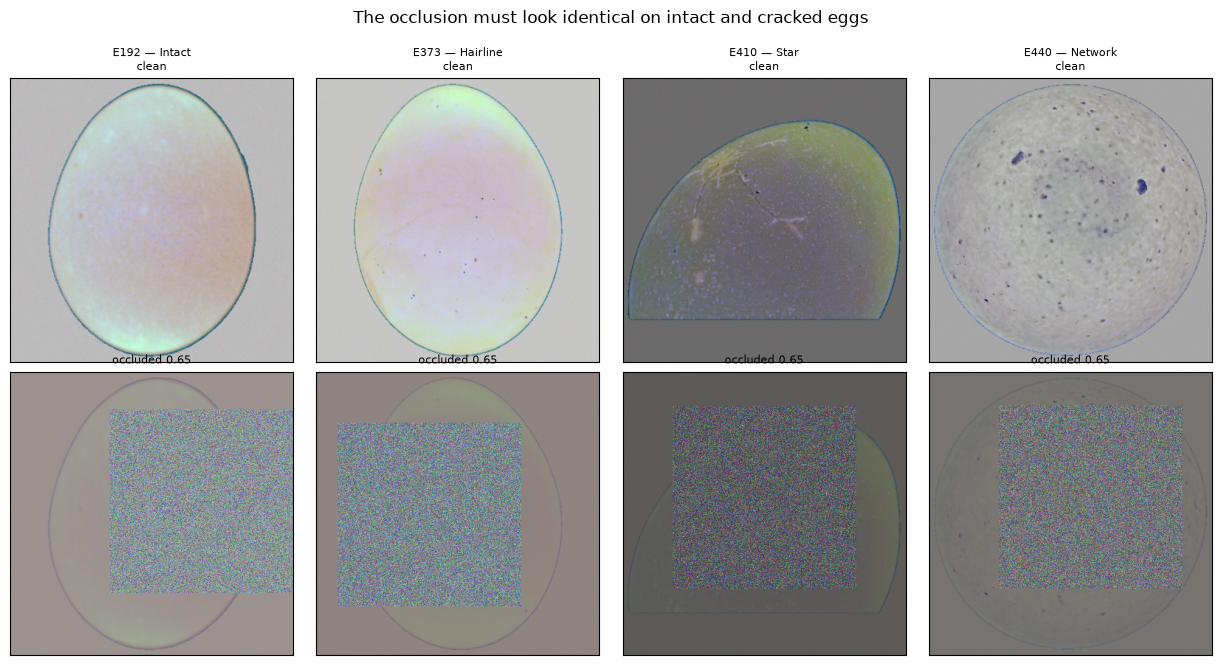

Check this figure before trusting any number below: if the intact eggs are visibly
different from the cracked ones in the bottom row, the control is still leaking.


In [4]:
# --- visual confirmation that the occlusion looks the same on both classes
cache = np.load(CACHE_PATH, mmap_mode="r")
import cv2
f_show = BOX_FRACTIONS[-1]
picks = []
for cls in CFG.LABEL4:
    sub = splits[splits["label4"].eq(cls) & splits["split"].eq("dev")]
    picks.append(sub.index[len(sub) // 2])

fig, axes = plt.subplots(2, len(picks), figsize=(3.1 * len(picks), 6.6))
for j, r in enumerate(picks):
    ds_clean = EggDataset(CACHE_PATH, [r], LABELS, TRAIN_SIDE, policy=None, masks=MASKS)
    ds_occ = EggDataset(CACHE_PATH, [r], LABELS, TRAIN_SIDE, policy=None, masks=MASKS,
                        occlude_crack=True, occlude_box_frac=f_show)
    for row, ds, lab in [(0, ds_clean, "clean"), (1, ds_occ, f"occluded {f_show}")]:
        x = ds[0]["image"].numpy().transpose(1, 2, 0)
        x = (x - x.min()) / (x.max() - x.min() + 1e-9)
        axes[row, j].imshow(x)
        axes[row, j].set_title(f"{splits.loc[r, 'egg_id']} — {splits.loc[r, 'label4']}\n{lab}"
                               if row == 0 else lab, fontsize=8)
        axes[row, j].set_xticks([]); axes[row, j].set_yticks([]); axes[row, j].grid(False)
fig.suptitle("The occlusion must look identical on intact and cracked eggs", y=1.0, fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_occlusion_examples.png", bbox_inches="tight")
plt.show()
print("Check this figure before trusting any number below: if the intact eggs are visibly")
print("different from the cracked ones in the bottom row, the control is still leaking.")

---
## 2. Run the control

In [5]:
def fold_rows(k):
    tr = splits.index[(splits["split"].eq("dev")) & (splits["fold"] != k)].to_numpy()
    va = splits.index[(splits["split"].eq("dev")) & (splits["fold"] == k)].to_numpy()
    return tr, va

def already(tag, fold):
    if not RUNS_CSV.exists():
        return False
    try:
        d = pd.read_csv(RUNS_CSV)
    except Exception:
        return False
    return bool(len(d) and "tag" in d.columns
                and ((d["tag"] == tag) & (d["fold"] == fold)).any())

PRED_DIR = OUT / "predictions"; PRED_DIR.mkdir(parents=True, exist_ok=True)

if RUN_CONTROL:
    for f in BOX_FRACTIONS:
        tag = f"control_box{int(f * 100)}"
        print(f"\n{'=' * 60}\nocclusion square {f} ({int(f * TRAIN_SIDE)} px)\n{'=' * 60}")
        for k in range(N_FOLDS):
            if already(tag, k):
                print(f"  fold {k}: already recorded"); continue
            tr, va = fold_rows(k)
            cfg = TrainConfig(backbone=BACKBONE, formulation=FORMULATION, n_out=4,
                              policy=POLICY, train_side=TRAIN_SIDE, epochs=EPOCHS,
                              physical_batch=PHYS_BATCH, effective_batch=EFFECTIVE_BATCH,
                              patience=PATIENCE, num_workers=NUM_WORKERS,
                              seed=CFG.RANDOM_SEED + k, occlude_crack=True, tag=tag)
            ds_tr = EggDataset(CACHE_PATH, tr, LABELS, TRAIN_SIDE, policy=POLICY, masks=MASKS,
                               occlude_crack=True, occlude_box_frac=f)
            ds_va = EggDataset(CACHE_PATH, va, LABELS, TRAIN_SIDE, policy=None, masks=MASKS,
                               occlude_crack=True, occlude_box_frac=f)
            ltr = make_loader(ds_tr, PHYS_BATCH, True, NUM_WORKERS)
            lva = make_loader(ds_va, PHYS_BATCH, False, NUM_WORKERS)
            w4 = class_weights(y4[tr], 4)
            m, _, state = train_fold(cfg, ltr, lva, device, w4, None, None, verbose=False)
            append_run(RUNS_CSV, cfg, k, m,
                       {"n_train": len(tr), "n_val": len(va), "box_frac": f})
            # keep per-egg predictions so the coverage subset can be analysed
            from common.models import build_model
            mdl = build_model(BACKBONE, FORMULATION, 4, pretrained=False,
                              img_size=TRAIN_SIDE)
            mdl.load_state_dict(state); mdl.to(device).eval()
            p = predict(mdl, lva, device, cfg)
            np.savez(PRED_DIR / f"{tag}_fold{k}.npz",
                     idx=p["idx"], y4=p["y4"], y2=p["y2"],
                     pred4=p["logits"].argmax(1))
            del mdl; torch.cuda.empty_cache()
            print(f"  fold {k}: macroF1 {m['macro_f1']:.4f}  "
                  f"bin {m.get('macro_f1_binary', float('nan')):.4f}")
else:
    print("control not run")


occlusion square 0.45 (172 px)


  fold 0: macroF1 0.7621  bin 0.8375
  fold 1: macroF1 0.7162  bin 0.8468
  fold 2: macroF1 0.6331  bin 0.7467
  fold 3: macroF1 0.6960  bin 0.8736
  fold 4: macroF1 0.7531  bin 0.8908

occlusion square 0.65 (249 px)
  fold 0: macroF1 0.7028  bin 0.8191
  fold 1: macroF1 0.7040  bin 0.8378
  fold 2: macroF1 0.6024  bin 0.7711
  fold 3: macroF1 0.6212  bin 0.8642
  fold 4: macroF1 0.6586  bin 0.8726


---
## 3. Results, including the fully-covered subset

The overall numbers mix eggs whose crack was removed with eggs whose crack was only partly removed.
The subset restricted to fully covered cracks is the unambiguous measurement, and it is the one
quoted in Chapter 5.

In [6]:
runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
res_rows = []
for f in BOX_FRACTIONS:
    tag = f"control_box{int(f * 100)}"
    r = runs[runs["tag"].eq(tag)] if len(runs) and "tag" in runs.columns else pd.DataFrame()
    if not len(r):
        continue
    res_rows.append({"condition": f"occluded {f} ({int(f*TRAIN_SIDE)}px, "
                                  f"{100*cov[cov['cracked']][f'covered_{f}'].mean():.0f}% covered)",
                     "four_class": round(r["macro_f1"].mean(), 4),
                     "four_class_sd": round(r["macro_f1"].std(), 4),
                     "binary": round(r["macro_f1_binary"].mean(), 4)})
if res_rows:
    res = pd.DataFrame(res_rows)
    ref = pd.DataFrame([{"condition": "clean (crack intact)",
                         "four_class": BASELINE["clean_4class"], "four_class_sd": 0.0316,
                         "binary": BASELINE["clean_binary"]},
                        {"condition": "acquisition floor (no pixels)",
                         "four_class": BASELINE["floor_4class"], "four_class_sd": np.nan,
                         "binary": BASELINE["floor_binary"]}])
    res = pd.concat([ref.iloc[:1], res, ref.iloc[1:]], ignore_index=True).set_index("condition")
    res.to_csv(TAB_DIR / "t02_control_results.csv")
    S["control"] = res.reset_index().to_dict("records")
    print(res.to_string())

    worst = res.iloc[-2]
    drop4 = BASELINE["clean_4class"] - worst["four_class"]
    span4 = BASELINE["clean_4class"] - BASELINE["floor_4class"]
    share = drop4 / max(span4, 1e-9)
    S["crack_share_overall"] = round(float(share), 3)
    print(f"\nat the largest square: four-class falls {drop4:+.4f}, which is "
          f"{share:.0%} of the distance from the clean result to the acquisition floor")

                                    four_class  four_class_sd  binary
condition                                                            
clean (crack intact)                    0.7431         0.0316  0.8717
occluded 0.45 (172px, 65% covered)      0.7121         0.0517  0.8391
occluded 0.65 (249px, 95% covered)      0.6578         0.0463  0.8330
acquisition floor (no pixels)           0.2950            NaN  0.5650

at the largest square: four-class falls +0.0853, which is 19% of the distance from the clean result to the acquisition floor


In [7]:
# --- subset analysis on eggs whose crack was fully covered -----------------
sub_rows = []
for f in BOX_FRACTIONS:
    tag = f"control_box{int(f * 100)}"
    files = sorted(PRED_DIR.glob(f"{tag}_fold*.npz"))
    if not files:
        continue
    idx, yt4, yp4 = [], [], []
    for fp in files:
        z = np.load(fp)
        idx.append(z["idx"]); yt4.append(z["y4"]); yp4.append(z["pred4"])
    idx = np.concatenate(idx); yt4 = np.concatenate(yt4); yp4 = np.concatenate(yp4)
    covered = cov[f"covered_{f}"].to_numpy()[idx]
    is_cracked = (yt4 > 0)
    # eggs we can speak about without caveat: intact eggs plus cracked eggs fully covered
    keep = (~is_cracked) | covered
    sub_rows.append({
        "box_frac": f,
        "n_eggs": int(keep.sum()),
        "n_cracked_fully_covered": int((is_cracked & covered).sum()),
        "four_class_all": round(float(f1_score(yt4, yp4, average="macro", zero_division=0)), 4),
        "four_class_covered_only": round(float(
            f1_score(yt4[keep], yp4[keep], average="macro", zero_division=0)), 4),
        "detection_recall_covered": round(float(recall_score(
            (yt4[is_cracked & covered] > 0).astype(int),
            (yp4[is_cracked & covered] > 0).astype(int), zero_division=0)), 4),
    })
if sub_rows:
    sub = pd.DataFrame(sub_rows).set_index("box_frac")
    sub.to_csv(TAB_DIR / "t03_covered_subset.csv")
    S["covered_subset"] = sub.reset_index().to_dict("records")
    print(sub.to_string())
    print("\ndetection_recall_covered is the sharpest single number: of the cracked eggs whose")
    print("crack was definitely removed, what fraction does the model still call cracked?")
    print("Near 1.0 means it is reading context. Near the intact-egg false-positive rate means")
    print("it was reading the crack.")

          n_eggs  n_cracked_fully_covered  four_class_all  four_class_covered_only  detection_recall_covered
box_frac                                                                                                    
0.45         456                      186          0.7133                   0.6953                    0.7903
0.65         540                      270          0.6654                   0.6693                    0.8667

detection_recall_covered is the sharpest single number: of the cracked eggs whose
crack was definitely removed, what fraction does the model still call cracked?
Near 1.0 means it is reading context. Near the intact-egg false-positive rate means
it was reading the crack.


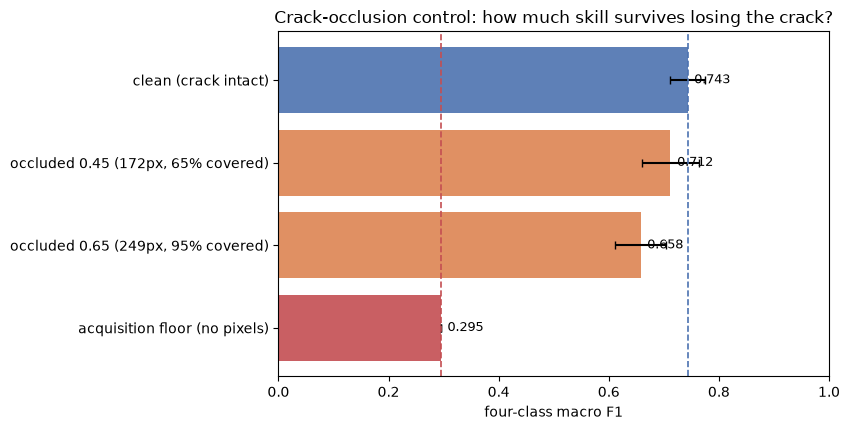

NOTEBOOK 05c DIGEST -- CRACK-OCCLUSION CONTROL
generated: 2026-10-08T18:18:46
model: efficientnet_b0 + single4

clean reference      4cls 0.7431  bin 0.8717
acquisition floor    4cls 0.295  bin 0.565

   clean (crack intact)                           4cls 0.7431  bin 0.8717
   occluded 0.45 (172px, 65% covered)             4cls 0.7121  bin 0.8391
   occluded 0.65 (249px, 95% covered)             4cls 0.6578  bin 0.833
   acquisition floor (no pixels)                  4cls 0.295  bin 0.565

FULLY-COVERED SUBSET
   box 0.45: n_covered 186  4cls_all 0.7133  4cls_covered 0.6953  det_recall 0.7903
   box 0.65: n_covered 270  4cls_all 0.6654  4cls_covered 0.6693  det_recall 0.8667

SHARE OF SKILL ATTRIBUTABLE TO THE CRACK: 19%


In [ ]:
if res_rows:
    fig, ax = plt.subplots(figsize=(8.6, 4.4))
    names = list(res.index)
    vals = res["four_class"].to_numpy()
    cols = ["#4C72B0"] + ["#DD8452"] * (len(names) - 2) + ["#C44E52"]
    ax.barh(names, vals, color=cols, alpha=0.9,
            xerr=res["four_class_sd"].fillna(0).to_numpy(), capsize=3)
    for i, v in enumerate(vals):
        ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=9)
    ax.axvline(BASELINE["floor_4class"], ls="--", color="#C44E52", lw=1.2)
    ax.axvline(BASELINE["clean_4class"], ls="--", color="#4C72B0", lw=1.2)
    ax.invert_yaxis(); ax.set_xlim(0, 1.0)
    ax.set_xlabel("four-class macro F1")
    ax.set_title("Crack-occlusion control: how much skill survives losing the crack?")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "02_control_results.png", bbox_inches="tight")
    plt.show()

def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "control_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

L = ["=" * 70, "NOTEBOOK 05c DIGEST -- CRACK-OCCLUSION CONTROL", "=" * 70,
     f"generated: {S['generated_at']}",
     f"model: {BACKBONE} + {FORMULATION}", "",
     f"clean reference      4cls {BASELINE['clean_4class']}  bin {BASELINE['clean_binary']}",
     f"acquisition floor    4cls {BASELINE['floor_4class']}  bin {BASELINE['floor_binary']}", ""]
for r in S.get("control", []):
    L.append(f"   {r['condition']:<46s} 4cls {r['four_class']}  bin {r['binary']}")
if "covered_subset" in S:
    L += ["", "FULLY-COVERED SUBSET"]
    for r in S["covered_subset"]:
        L.append(f"   box {r['box_frac']}: n_covered {r['n_cracked_fully_covered']}  "
                 f"4cls_all {r['four_class_all']}  4cls_covered {r['four_class_covered_only']}  "
                 f"det_recall {r['detection_recall_covered']}")
if "crack_share_overall" in S:
    L += ["", f"SHARE OF SKILL ATTRIBUTABLE TO THE CRACK: {S['crack_share_overall']:.0%}"]
L.append("=" * 70)
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)